In [13]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

metric = "balanced_accuracy"  # "balanced_accuracy", "f1"
modes = ["bare", "ifc", "projection", "combined", "mlp_standardized", "mlp_raw"]

df = pd.read_csv(Path("../results") / "tabular.csv")


def mean_std(values, index, digits=3):
    stats = df.pivot_table(index=index, columns="mode", values=values, aggfunc=["mean", "std"])
    text = stats.map(f"{{:.{digits}f}}".format)  # std is nan when a cell has a single run
    return (text["mean"] + " ± " + text["std"])[modes].replace("nan ± nan", "")


## Mean ± std over seeds, per dataset and mode.

In [14]:
table = df.pivot_table(index="dataset", columns="mode", values=metric)[modes]
mean_std(metric, "dataset")

mode,bare,ifc,projection,combined,mlp_standardized,mlp_raw
dataset,,,,,,
arcene,0.772 ± 0.060,0.776 ± 0.079,0.756 ± 0.078,0.768 ± 0.065,0.701 ± 0.090,0.531 ± 0.176
bank_marketing,0.711 ± 0.015,0.715 ± 0.014,0.677 ± 0.002,0.693 ± 0.013,0.724 ± 0.032,0.675 ± 0.009
letter,0.966 ± 0.002,0.966 ± 0.001,0.960 ± 0.002,0.961 ± 0.003,0.934 ± 0.011,0.932 ± 0.002
madelon,0.711 ± 0.013,0.716 ± 0.011,0.703 ± 0.011,0.712 ± 0.009,0.561 ± 0.006,0.511 ± 0.023
musk_v2,0.983 ± 0.010,0.982 ± 0.007,0.984 ± 0.008,0.984 ± 0.010,0.983 ± 0.007,0.971 ± 0.012
satimage,0.899 ± 0.010,0.897 ± 0.008,0.896 ± 0.008,0.894 ± 0.009,0.874 ± 0.014,0.870 ± 0.015
spambase,0.953 ± 0.006,0.954 ± 0.005,0.949 ± 0.005,0.948 ± 0.004,0.929 ± 0.010,0.922 ± 0.009
support2,0.863 ± 0.003,0.866 ± 0.004,0.864 ± 0.006,0.864 ± 0.004,0.840 ± 0.016,0.505 ± 0.007
tuandromd,0.992 ± 0.002,0.991 ± 0.002,0.991 ± 0.002,0.991 ± 0.002,0.983 ± 0.008,0.982 ± 0.008


## Difference from bare (positive = the addition helps).

In [15]:
diff = table.drop(columns="bare").sub(table["bare"], axis=0).round(4)
diff

mode,ifc,projection,combined,mlp_standardized,mlp_raw
dataset,,,,,
arcene,0.0041,-0.0165,-0.0038,-0.0713,-0.2412
bank_marketing,0.0041,-0.0342,-0.0180,0.0131,-0.0361
letter,0.0006,-0.0058,-0.0044,-0.0320,-0.0339
madelon,0.0054,-0.0077,0.0013,-0.1495,-0.2000
musk_v2,-0.0004,0.0014,0.0016,0.0002,-0.0114
satimage,-0.0019,-0.0031,-0.0044,-0.0252,-0.0283
spambase,0.0015,-0.0037,-0.0048,-0.0236,-0.0309
support2,0.0027,0.0010,0.0009,-0.0228,-0.3578
tuandromd,-0.0003,-0.0008,-0.0007,-0.0084,-0.0099


## average gain and win/tie/loss counts over datasets.

In [16]:
pd.DataFrame({
    "mean_diff": diff.mean(),
    "std_diff": diff.std(),
    "wins": (diff > 0).sum(),
    "ties": (diff == 0).sum(),
    "losses": (diff < 0).sum(),
}).round(4)

,mean_diff,std_diff,wins,ties,losses
mode,,,,,
ifc,0.0016,0.0024,6,1,3
projection,-0.0168,0.0307,2,0,8
combined,-0.0126,0.0290,3,0,7
mlp_standardized,-0.0523,0.0703,2,0,8
mlp_raw,-0.1334,0.1492,0,0,10


## Average rank (1 = best) 

In [17]:
print(table.rank(axis=1, ascending=False).mean().round(2))

mode
bare                2.35
ifc                 1.75
projection          3.50
combined            3.00
mlp_standardized    4.40
mlp_raw             6.00
dtype: float64


## mean and std of training time, inference time and  depth 

In [18]:
df.groupby("mode")[["fit_seconds", "predict_seconds", "n_layers"]].agg(["mean", "std"]).round(2)

fit_seconds          predict_seconds       n_layers      
                        mean      std            mean   std     mean   std
mode                                                                      
bare                   45.77    41.61            0.20  0.26     2.27  1.06
combined              106.75   214.80            0.36  0.69     2.54  1.29
ifc                  1525.65  9969.80            0.21  0.33     2.44  1.24
mlp_raw                23.37    92.67            0.01  0.02    10.00  0.00
mlp_standardized        8.37    15.76            0.01  0.01    10.00  0.00
projection            159.91   468.85            0.22  0.25     2.29  1.50

## number of layers

In [19]:
display(pd.crosstab(df["n_layers"], df["mode"])[modes])
# mean_std(metric, "n_layers")

mode,bare,ifc,projection,combined,mlp_standardized,mlp_raw
n_layers,,,,,,
1,12,11,13,8,0,0
2,21,19,21,23,0,0
3,8,9,8,6,0,0
4,7,4,4,7,0,0
5,1,5,1,2,0,0
6,0,0,0,2,0,0
10,0,0,1,0,48,47


In [20]:
df["relative"] = df[metric] - df.groupby("dataset")[metric].transform("mean")
mean_std("relative", "n_layers", digits=4)

mode,bare,ifc,projection,combined,mlp_standardized,mlp_raw
n_layers,,,,,,
1,0.0700 ± 0.0654,0.0755 ± 0.0655,0.0134 ± 0.0314,0.0134 ± 0.0375,,
2,0.0190 ± 0.0246,0.0205 ± 0.0236,0.0148 ± 0.0330,0.0200 ± 0.0264,,
3,0.0175 ± 0.0228,0.0265 ± 0.0310,0.0247 ± 0.0252,0.0190 ± 0.0269,,
4,0.0457 ± 0.0448,0.0243 ± 0.0365,0.0259 ± 0.0299,0.0434 ± 0.0409,,
5,0.0612 ± nan,0.0527 ± 0.0729,0.1322 ± nan,0.0343 ± 0.0461,,
6,,,,0.0517 ± 0.0658,,
10,,,0.0592 ± nan,,-0.0186 ± 0.0530,-0.1026 ± 0.1222


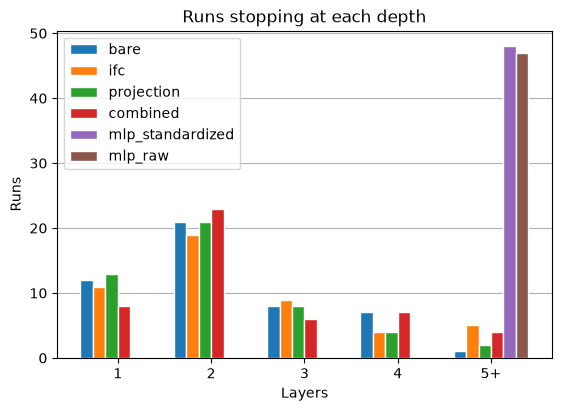

In [21]:
layers = df["n_layers"].clip(upper=5)
labels = ["1", "2", "3", "4", "5+"]

fig, ax = plt.subplots(figsize=(5.5, 4), layout="constrained")

counts = pd.crosstab(layers, df["mode"])[modes]
counts.plot.bar(ax=ax, width=0.8, edgecolor="white", rot=0)

ax.set_xticks(range(5), labels)
ax.set(title="Runs stopping at each depth", xlabel="Layers", ylabel="Runs")

ax.grid(axis="y")
ax.set_axisbelow(True)
plt.legend()
plt.show()